# Fine-tuning Gemma 3 4B on Khmer Banking Questions

**ACLEDA first, ABA second, then compare**

I use two CSV datasets for one assignment. I do **not** mix their training data. First, I train Gemma 3 with ACLEDA questions and save its LoRA adapter. Next, I load a **fresh copy of the same base model** and train it on ABA. At the end, I compare the real loss curves and test both adapters on the same questions.

**Start:** In Colab select **Runtime → Change runtime type → T4 GPU**. Run cells from top to bottom, and upload **both CSV files at the same time** when asked. My files can be named `dataasilida_fully_cleaned(2).csv` and `aba_query(1).csv`; the upload cell recognizes them. No ZIP is needed.

**Important:** I need a GPU and enough Colab runtime. The notebook contains **no invented training results**. I should download my result ZIP when finished because Colab sessions can reset.



I use **Gemma 3 4B**, a pretrained language model, for a Khmer banking Q&A task. Fine-tuning means teaching the model with examples of questions and answers. I use **PEFT** (parameter-efficient fine-tuning), specifically **LoRA**, to train small adapter weights instead of updating the whole model. Loading the model in 4-bit helps it fit on a Colab GPU.

My steps are simple: load the data → clean it → split train/validation/test → format Q&A as chat messages → fine-tune → check losses → test answers. **Training loss** tells me how the model fits the examples it sees. **Validation loss** checks held-out examples during training. **Test questions** are saved for the final comparison.

For ABA, different questions can share the same answer because the file contains paraphrases. I keep those related examples in the **same split** to reduce data leakage. For ACLEDA, I group identical questions together.

In [1]:
%pip -q install -U unsloth trl datasets peft accelerate bitsandbytes scikit-learn pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


In [3]:
# Upload my two CSVs. No ZIP or fixed filename needed.
from unsloth import FastModel, is_bfloat16_supported
from unsloth.chat_templates import get_chat_template, train_on_responses_only
from trl import SFTTrainer, SFTConfig
from datasets import Dataset
from sklearn.model_selection import GroupShuffleSplit
from google.colab import files
from IPython.display import display
from pathlib import Path
from io import BytesIO
from collections import Counter
import pandas as pd, numpy as np, matplotlib.pyplot as plt, torch, gc, shutil

OUT = Path('/content/gemma_bank_homework')
OUT.mkdir(exist_ok=True)

uploaded = files.upload()  # Select ACLEDA CSV and ABA CSV together.
raw = {}
for filename, data in uploaded.items():
    name = filename.lower()
    bank = 'acleda' if ('acleda' in name or 'asilida' in name) else ('aba' if 'aba' in name else None)
    if bank is None or bank in raw or not name.endswith('.csv'):
        raise ValueError(f'Please upload one ACLEDA CSV and one ABA CSV, not: {filename}')
    raw[bank] = data
if set(raw) != {'acleda', 'aba'}:
    raise ValueError('Please select BOTH CSV files in the same upload window.')

def read_qa(data, bank):
    df = pd.read_csv(BytesIO(data), encoding='utf-8-sig')
    df.columns = df.columns.str.strip()
    if not {'Question', 'Answer'}.issubset(df.columns):
        raise ValueError(f'{bank} needs Question and Answer columns. Found: {df.columns.tolist()}')
    df = df[['Question', 'Answer']].dropna().copy()
    df['Question'] = df['Question'].astype(str).str.strip()
    df['Answer'] = df['Answer'].astype(str).str.strip()
    df = df[(df.Question != '') & (df.Answer != '')].drop_duplicates().reset_index(drop=True)
    (OUT / f'{bank}_input.csv').write_bytes(data)
    return df

a = read_qa(raw['acleda'], 'acleda')
b = read_qa(raw['aba'], 'aba')
summary = pd.DataFrame([
    ['ACLEDA', len(a), a.Question.nunique(), a.Answer.nunique()],
    ['ABA', len(b), b.Question.nunique(), b.Answer.nunique()]
], columns=['Dataset', 'Rows', 'Unique questions', 'Unique answers'])
display(summary)

Saving aba_query.csv to aba_query.csv
Saving dataasilida_fully_cleaned.csv to dataasilida_fully_cleaned (1).csv


,Dataset,Rows,Unique questions,Unique answers
0,ACLEDA,518,480,508
1,ABA,1344,1344,224


,Train,Validation,Test
Bank,,,
ACLEDA,419,49,50
ABA,1074,132,138


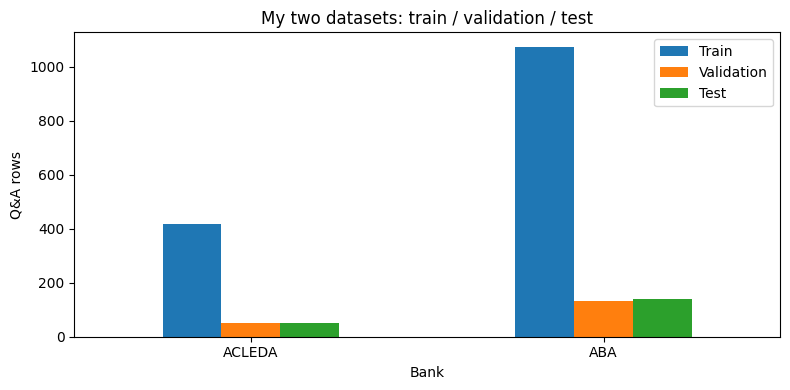

In [4]:
# Split both banks without putting related Q&A in different splits.
SEED = 42

def split_qa(df, group_col):
    groups = df[group_col].str.casefold()
    splitter = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=SEED)
    train_ids, rest_ids = next(splitter.split(df, groups=groups))
    train, rest = df.iloc[train_ids], df.iloc[rest_ids]
    half = GroupShuffleSplit(n_splits=1, test_size=.50, random_state=SEED)
    val_ids, test_ids = next(half.split(rest, groups=rest[group_col].str.casefold()))
    val, test = rest.iloc[val_ids], rest.iloc[test_ids]
    parts = [x.reset_index(drop=True) for x in (train, val, test)]
    keys = [set(x[group_col].str.casefold()) for x in parts]
    assert not(keys[0] & keys[1] or keys[0] & keys[2] or keys[1] & keys[2])
    return parts

train_a, val_a, test_a = split_qa(a, 'Question')
train_b, val_b, test_b = split_qa(b, 'Answer')  # Important for paraphrased ABA questions
sizes = pd.DataFrame({
    'Bank':['ACLEDA','ABA'],
    'Train':[len(train_a),len(train_b)],
    'Validation':[len(val_a),len(val_b)],
    'Test':[len(test_a),len(test_b)]
}).set_index('Bank')
display(sizes)
sizes.plot.bar(rot=0, title='My two datasets: train / validation / test', figsize=(8,4))
plt.ylabel('Q&A rows'); plt.tight_layout()
plt.savefig(OUT/'01_dataset_sizes.png', dpi=150); plt.show()

## Objective 2 — Notebook configuration

I keep the **same model and settings** for both experiments so I can focus on the different datasets. These are short homework runs, not a production chatbot.

| Setting | My choice | Why I use it |
|---|---:|---|
| Model | Gemma 3 4B Instruct | Same starting model for both banks |
| LoRA rank | 8 | Small number of trainable adapter parameters |
| Learning rate | 0.0001 | Controls the size of weight updates |
| Batch / accumulation | 1 / 8 | Effective batch size of 8, suitable for limited GPU memory |
| Maximum length | 1024 tokens | Limits memory used per example |
| Maximum steps | 100 | A manageable first experiment |
| Validation | Every 10 steps | Lets me follow validation loss |

The learning rate and number of steps affect how fast the model learns. Larger settings are not always better. I will compare the training and validation curves before deciding whether more training is useful.

In [5]:
MODEL = 'unsloth/gemma-3-4b-it'
MAX_LEN, MAX_STEPS, LR = 1024, 100, 1e-4
LORA_R, BATCH, ACCUM = 8, 1, 8
EVAL_STEPS = 10
print('Effective batch size:', BATCH * ACCUM)
print('Training order: ACLEDA -> ABA -> compare')

Effective batch size: 8
Training order: ACLEDA -> ABA -> compare


In [6]:
# This function ALWAYS loads a fresh base model for each bank.
def train_bank(bank, train_df, val_df):
    history_file = OUT / f'{bank}_history.csv'
    adapter = OUT / f'{bank}_adapter'
    if history_file.exists() and (adapter / 'adapter_config.json').exists():
        print(bank, 'already saved; not training twice.')
        return
    if not torch.cuda.is_available():
        raise RuntimeError('Select a GPU in Runtime > Change runtime type.')

    model, tok = FastModel.from_pretrained(model_name=MODEL,
                                           max_seq_length=MAX_LEN, load_in_4bit=True)
    model = FastModel.get_peft_model(
        model, r=LORA_R, lora_alpha=16, lora_dropout=0, bias='none',
        finetune_vision_layers=False, finetune_language_layers=True,
        finetune_attention_modules=True, finetune_mlp_modules=True,
        random_state=SEED)
    tok = get_chat_template(tok, chat_template='gemma-3')

    def to_dataset(df):
        texts = [tok.apply_chat_template(
            [{'role':'user','content':q}, {'role':'assistant','content':ans}],
            tokenize=False, add_generation_prompt=False)
            for q, ans in df[['Question','Answer']].itertuples(index=False, name=None)]
        return Dataset.from_dict({'text':texts})

    config = SFTConfig(
        output_dir=str(OUT / f'checkpoints_{bank}'),
        dataset_text_field='text', max_length=MAX_LEN, packing=False,
        max_steps=MAX_STEPS, learning_rate=LR,
        per_device_train_batch_size=BATCH, gradient_accumulation_steps=ACCUM,
        per_device_eval_batch_size=1, logging_steps=5,
        eval_strategy='steps', eval_steps=EVAL_STEPS,
        save_strategy='no', optim='adamw_8bit',
        fp16=not is_bfloat16_supported(), bf16=is_bfloat16_supported(),
        gradient_checkpointing=True, report_to='none', seed=SEED)
    trainer = SFTTrainer(model=model, args=config,
                         train_dataset=to_dataset(train_df),
                         eval_dataset=to_dataset(val_df), processing_class=tok)
    trainer = train_on_responses_only(
        trainer, instruction_part='<start_of_turn>user\n',
        response_part='<start_of_turn>model\n')
    batch = next(iter(trainer.get_train_dataloader()))
    if not (batch['labels'] != -100).any().item():
        raise RuntimeError('No answer tokens found. Check the Gemma chat template.')

    trainer.train()
    trainer.evaluate()
    pd.DataFrame(trainer.state.log_history).to_csv(history_file, index=False)
    trainer.model.save_pretrained(str(adapter))
    tok.save_pretrained(str(adapter))
    print(f'{bank.upper()} finished. Loss history and LoRA adapter saved to {OUT}')
    del trainer, model, tok
    gc.collect(); torch.cuda.empty_cache()

### Step 1 — Train ACLEDA

I start with ACLEDA only. I use its training set for learning and its validation set to monitor loss. When it finishes, I save the loss history and LoRA adapter. I need this step to finish before starting ABA.

In [7]:
train_bank('acleda', train_a, val_a)
assert (OUT/'acleda_history.csv').exists()
assert (OUT/'acleda_adapter'/'adapter_config.json').exists()
print('Step 1 complete: ACLEDA.')

==((====))==  Unsloth 2026.11.12: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

`torch_dtype` is deprecated! Use `dtype` instead!


Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/419 [00:00<?, ? examples/s]

... (8 outputs left out)

Filter:   0%|          | 0/49 [00:00<?, ? examples/s]

Training Loss,Validation Loss,Step
1.276373,1.210624,100


Unsloth: Restored added_tokens_decoder metadata in /content/gemma_bank_homework/acleda_adapter/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/gemma_bank_homework/acleda_adapter.


ACLEDA finished. Loss history and LoRA adapter saved to /content/gemma_bank_homework
Step 1 complete: ACLEDA.


### Step 2 — Train ABA

Now I fine-tune **another fresh Gemma 3 4B** on ABA. I use the same hyperparameters as ACLEDA, but save a different adapter. This is **not continued training on the ACLEDA adapter** and it is **not a mixed dataset**.

In [8]:
assert (OUT/'acleda_adapter'/'adapter_config.json').exists(), 'Finish ACLEDA first.'
train_bank('aba', train_b, val_b)
assert (OUT/'aba_history.csv').exists()
assert (OUT/'aba_adapter'/'adapter_config.json').exists()
print('Step 2 complete: ABA. Both models are ready.')

==((====))==  Unsloth 2026.11.12: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/1074 [00:00<?, ? examples/s]

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/132 [00:00<?, ? examples/s]

... (5 outputs left out)

Filter:   0%|          | 0/132 [00:00<?, ? examples/s]

Training Loss,Validation Loss,Step
0.995568,1.645002,100


Unsloth: Restored added_tokens_decoder metadata in /content/gemma_bank_homework/aba_adapter/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/gemma_bank_homework/aba_adapter.


ABA finished. Loss history and LoRA adapter saved to /content/gemma_bank_homework
Step 2 complete: ABA. Both models are ready.


## Objective 3 — Training loss and validation loss

I look at both curves, not just the last training number. If training and validation loss both go down, the model is probably learning the task. If training loss goes down but validation loss starts to rise, that can indicate **overfitting**. If neither curve improves much, the model may be **underfitting**. These are signs to investigate, not automatic proof.

Because ACLEDA and ABA contain different Q&A examples, their raw loss numbers are not a perfect measure of which model is better. I also test both adapters on **exactly the same questions** in Objective 4.

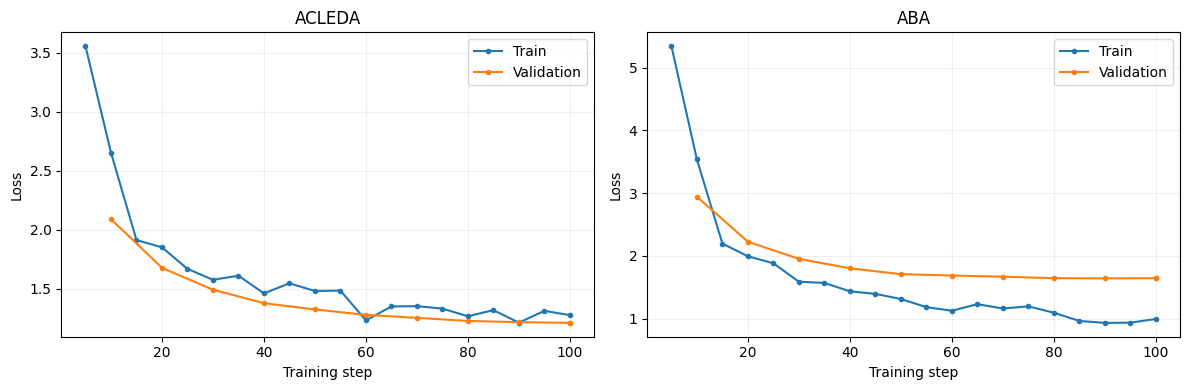

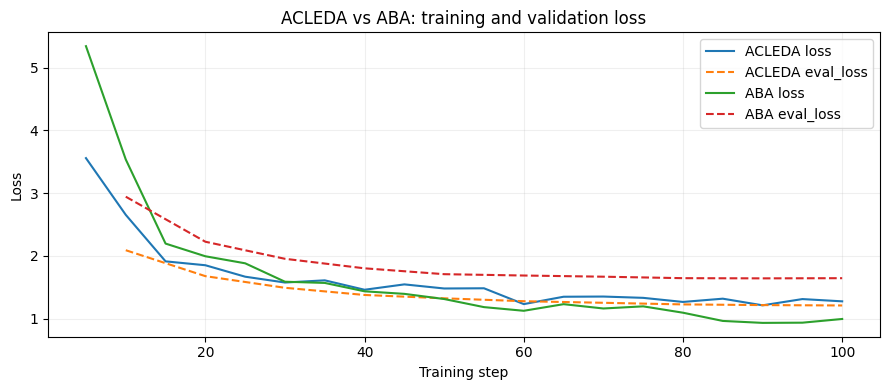

In [9]:
# Plot real histories: one panel per dataset + one direct comparison.
hist = {bank:pd.read_csv(OUT/f'{bank}_history.csv') for bank in ['acleda','aba']}
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for ax, bank in zip(axes, ['acleda','aba']):
    h = hist[bank]
    for col, label in [('loss','Train'), ('eval_loss','Validation')]:
        if col in h:
            points = h[['step',col]].dropna()
            ax.plot(points.step, points[col], marker='o', ms=3, label=label)
    ax.set(title=bank.upper(), xlabel='Training step', ylabel='Loss')
    ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); plt.savefig(OUT/'02_each_bank_loss.png',dpi=150); plt.show()

plt.figure(figsize=(9,4))
for bank in ['acleda','aba']:
    h = hist[bank]
    for col, style in [('loss','-'), ('eval_loss','--')]:
        points = h[['step',col]].dropna()
        plt.plot(points.step, points[col], style, label=f'{bank.upper()} {col}')
plt.xlabel('Training step'); plt.ylabel('Loss')
plt.title('ACLEDA vs ABA: training and validation loss')
plt.grid(alpha=.2); plt.legend(); plt.tight_layout()
plt.savefig(OUT/'03_loss_comparison.png',dpi=150); plt.show()

In [10]:
# A small table helps me describe the actual graphs.
loss_rows = []
for bank, h in hist.items():
    tr, va = h['loss'].dropna(), h['eval_loss'].dropna()
    loss_rows.append([bank.upper(), tr.iloc[0], tr.iloc[-1],
                      va.iloc[0], va.iloc[-1], va.min()])
loss_table = pd.DataFrame(loss_rows, columns=[
    'Dataset','First train','Last train','First val','Last val','Best val'])
display(loss_table.round(4))
loss_table.to_csv(OUT/'loss_summary.csv', index=False)

,Dataset,First train,Last train,First val,Last val,Best val
0,ACLEDA,3.5569,1.2764,2.0905,1.2106,1.2106
1,ABA,5.3398,0.9956,2.9427,1.6450,1.6424


**My observation after running:** For ACLEDA, I saw the training loss ______ and validation loss ______. For ABA, I saw ______. I think ______ may be overfitting / underfitting / learning normally because ______. I should use the graph and actual numbers to fill this in, rather than guessing.

## Objective 4 — Practical experiment: compare ACLEDA and ABA

The main question is: **what changes when I fine-tune the same Gemma 3 4B with a different dataset?** To test it fairly, I make a small benchmark of **12 held-out ACLEDA questions and 12 held-out ABA questions**. Both adapters answer **all 24 questions**. That gives me a cross-bank comparison rather than judging each model on different test questions.

I report **exact match**, **character 3-gram recall** and **character 3-gram F1**. Exact match is strict; F1 measures text overlap. None of these alone proves that a banking answer is factually correct. I should read some real Khmer answers, too.

In [11]:
# Same 24 test questions for both adapters.
benchmark = pd.concat([
    test_a.drop_duplicates('Question').sample(12, random_state=SEED).assign(Bank='ACLEDA'),
    test_b.drop_duplicates('Answer').sample(12, random_state=SEED).assign(Bank='ABA')
], ignore_index=True).rename(columns={'Answer':'Reference'})
benchmark.insert(0, 'ID', [f'Q{i+1:02}' for i in range(len(benchmark))])
benchmark.to_csv(OUT/'same_24_test_questions.csv', index=False, encoding='utf-8-sig')

def metrics(prediction, reference):
    p, r = ' '.join(str(prediction).split()), ' '.join(str(reference).split())
    grams = lambda s: Counter(s[i:i+3] for i in range(max(0, len(s)-2)))
    x, y = grams(p), grams(r)
    common = sum((x & y).values())
    precision = common / sum(x.values()) if x else 0
    recall = common / sum(y.values()) if y else 0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
    return int(p == r), recall, f1

def test_adapter(bank):
    adapter = OUT / f'{bank}_adapter'
    if not (adapter/'adapter_config.json').exists():
        raise FileNotFoundError(f'Finish training {bank} first.')
    model, tok = FastModel.from_pretrained(
        model_name=str(adapter), max_seq_length=MAX_LEN, load_in_4bit=True)
    tok = get_chat_template(tok, chat_template='gemma-3')
    model.eval()
    rows = []
    for row in benchmark.itertuples(index=False):
        prompt = tok.apply_chat_template(
            [{'role':'user','content':str(row.Question)}],
            tokenize=False, add_generation_prompt=True)
        inputs = tok([prompt], return_tensors='pt').to('cuda')
        with torch.inference_mode():
            output = model.generate(**inputs, max_new_tokens=256, do_sample=False)
        text_ids = output[0][inputs['input_ids'].shape[1]:]
        tokenizer = getattr(tok, 'tokenizer', tok)
        answer = tokenizer.decode(text_ids, skip_special_tokens=True).strip()
        exact, recall, f1 = metrics(answer, row.Reference)
        rows.append([row.ID, row.Bank, row.Question, row.Reference,
                     answer, exact, recall, f1])
    result = pd.DataFrame(rows, columns=[
        'ID','Bank','Question','Reference','Prediction','Exact','Recall','F1'])
    result.to_csv(OUT/f'{bank}_predictions.csv', index=False, encoding='utf-8-sig')
    del model, tok; gc.collect(); torch.cuda.empty_cache()
    return result

print('Benchmark ready:', len(benchmark), 'questions.')

Benchmark ready: 24 questions.


### Step 3 — Test both saved adapters

I now generate answers from each model, one at a time, and store the predictions. Testing does **not** train either model again. The first model has learned from ACLEDA; the second has learned from ABA.

In [12]:
pred_a = test_adapter('acleda')
pred_b = test_adapter('aba')
print('Both models tested on the same 24 questions.')

==((====))==  Unsloth 2026.11.12: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

,Bank,Model,Exact,Recall,F1
0,ABA,Trained on ABA,0.0,0.268,0.272
1,ABA,Trained on ACLEDA,0.0,0.361,0.302
2,ACLEDA,Trained on ABA,0.0,0.079,0.119
3,ACLEDA,Trained on ACLEDA,0.0,0.158,0.151


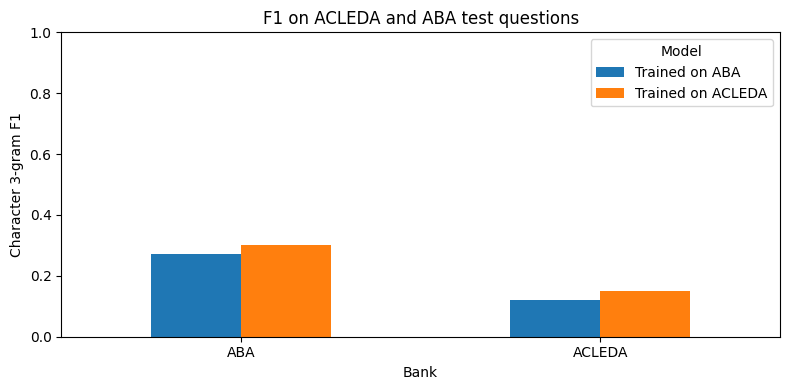

,Exact,Recall,F1
Model,,,
Trained on ABA,0.0,0.173,0.196
Trained on ACLEDA,0.0,0.260,0.227


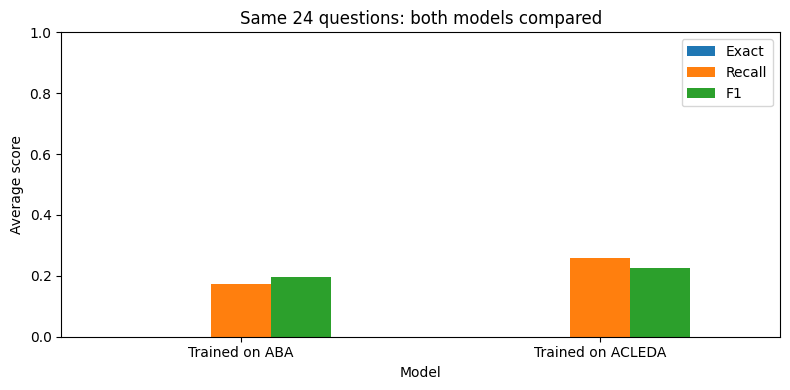

,ID,Bank,Question,Reference,ACLEDA answer,ABA answer
0,Q01,ACLEDA,តើអតិថិជនត្រូវធ្វើដូចម្តេចពេលបាត់បង់មូលប្បទានប...,\nក្នុងករណីខូចខាត ឬបាត់បង់មូលប្បទានប័ត្រទេសចរណ...,ប្រសិនបើអតិថិជនបាត់បង់មូលប្បទានប័ត្រទេសចរណ៍ ត្...,គួរជូនដំណឹងដល់ក្រុមហ៊ុនទេសចរណ៍ភ្លាមៗ និងស្នើឱ្...
1,Q02,ACLEDA,តើ អ៉ីអនវ៉លឡេត មានមុខងារអ្វីខ្លះ,អ៉ីអនវ៉លឡេត មានមុខងារដូចជា៖ \n ទូទាត់ថ្លៃទំនិញ...,អ៉ីអនវ៉លឡេត គឺជាក្រុមហ៊ុនផលិត និងចែកចាយ ផលិតផល...,អ៉ីអនវ៉លឡេតជាកម្មវិធីគ្រប់គ្រងការងារដែលគាំទ្រក...
2,Q03,ACLEDA,តើរបៀបទូទាត់នៃសេវាបញ្ជាអចិន្រ្តៃយ៍ ដូចម្តេចដែរ,តាមរយៈធនាគារ អេស៊ីលីដា អ្នកទទួលផលអាចនឹងជ្រើសរើ...,លោកអ្នកអាចទូទាត់សេវាបញ្ជាអចិន្រ្តៃយ៍ តាមរយៈ៖ \...,អ្នកប្រើអាចទូទាត់សេវាបញ្ជាអចិន្រ្តៃយ៍តាមបណ្តាញ...
3,Q04,ACLEDA,តើខ្ញុំ​ត្រូវធ្វើ​ដូចម្តេច​ប្រសិនបើ អ៉ីអនកាត រ...,សូម​លោកអ្នក​ធ្វើការ​ទំនាក់ទំនង​មក​កាន់​លេខ ០២៣...,ប្រសិនបើ​អ៉ីអនកាត​របស់​លោកអ្នក​ត្រូវបាន​ប្រើប្...,គួរពិនិត្យប្រវត្តិប្រតិបត្តិការគណនី និងសកម្មភា...
4,Q05,ACLEDA,តើសេវាមូលប្បទានប័ត្រសាច់ប្រាក់អាចចេញផ្សាយបានទំ...,ទំហំទឹកប្រាក់ដែលត្រូវចេញផ្សាយនៅលើមូលប្បទានប័ត្...,សេវាមូលប្បទានប័ត្រសាច់ប្រាក់អាចចេញផ្សាយបានទំហំ...,អាចជ្រើសទំហាត់ប្រាក់ដែលគាំទ្រតាមលក្ខខណ្ឌផលិតផល។


In [13]:
# Compare average scores on each bank's held-out questions.
assert pred_a[['ID','Bank','Question','Reference']].equals(
       pred_b[['ID','Bank','Question','Reference']])
all_scores = pd.concat([
    pred_a.assign(Model='Trained on ACLEDA'),
    pred_b.assign(Model='Trained on ABA')
])
by_bank = all_scores.groupby(['Bank','Model'], as_index=False)[['Exact','Recall','F1']].mean()
display(by_bank.round(3))
by_bank.to_csv(OUT/'scores_by_bank.csv', index=False)

by_bank.pivot(index='Bank',columns='Model',values='F1').plot.bar(rot=0,figsize=(8,4))
plt.title('F1 on ACLEDA and ABA test questions'); plt.ylabel('Character 3-gram F1')
plt.ylim(0,1); plt.tight_layout(); plt.savefig(OUT/'04_F1_by_bank.png',dpi=150); plt.show()

overall = all_scores.groupby('Model')[['Exact','Recall','F1']].mean()
display(overall.round(3))
overall.to_csv(OUT/'overall_scores.csv')
overall.plot.bar(rot=0,figsize=(8,4))
plt.title('Same 24 questions: both models compared'); plt.ylabel('Average score')
plt.ylim(0,1); plt.tight_layout(); plt.savefig(OUT/'05_overall_scores.png',dpi=150); plt.show()

examples = benchmark[['ID','Bank','Question','Reference']].copy()
examples['ACLEDA answer'] = pred_a.Prediction
examples['ABA answer'] = pred_b.Prediction
display(examples.head(5))
examples.to_csv(OUT/'answers_side_by_side.csv', index=False, encoding='utf-8-sig')

### My final conclusion (fill in using my actual results)

I trained Gemma 3 4B twice with LoRA, first on **ACLEDA** and then on **ABA**, using the same settings. In the loss graphs, I noticed ______. On the ACLEDA test questions, the stronger model was ______, and on ABA questions it was ______. One example I checked was ______; this helped me see ______.

I learned that a larger dataset does not always guarantee a better model. My ABA file has **1,344 rows, but only 224 distinct reference answers**, so many rows are paraphrased variations. This comparison is a small learning experiment; the **24-question test** and text-overlap metrics have limitations. Next time I would ______.

I should write this conclusion **after** seeing the real graphs and generated Khmer answers. I should also follow my teacher's rules about acknowledging AI help.

In [ ]:
# Download charts and CSV results after BOTH experiments finish.
results = OUT/'report_files'
results.mkdir(exist_ok=True)
for path in OUT.glob('*.csv'):
    shutil.copy2(path, results/path.name)
for path in OUT.glob('*.png'):
    shutil.copy2(path, results/path.name)
archive = shutil.make_archive('/content/Gemma3_ACLEDA_vs_ABA_Results','zip',results)
print('Saved report results:', archive)
files.download(archive)
# To keep the trained adapters, save the two *_adapter folders separately to Drive.